<a href="https://colab.research.google.com/github/ricvazquez/ColabFiles/blob/main/PracticaRegresionLinealMultiple.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Maestría en Inteligencia Artificial y Analítica de Datos

## Programación para Analítica Descriptiva y Predictiva - Marzo 2025
## Práctica: Práctica: Regresión Lineal Múltiple
---


## Datos del Estudiante

*   Apellidos y Nombre: Ricardo Vazquez Macias
*   Matrícula: 273509

---



##  Objetivo de aprendizaje
Al finalizar esta práctica, el estudiante será capaz de **aplicar regresión lineal múltiple utilizando Scikit-Learn para modelar la relación entre varias variables independientes y una variable dependiente**, verificar los supuestos del modelo, interpretar los coeficientes, analizar la correlación entre predictores y evaluar el rendimiento del modelo utilizando métricas como el MSE, RMSE y R².

Datos
Trabajarás con el archivo `advertising.csv`, que contiene información sobre el gasto publicitario en diferentes medios y las ventas obtenidas:

-`TV`: inversión en publicidad televisiva.

-`Radio`: inversión en publicidad en radio.

-`Newspaper`: inversión en publicidad en periódicos.

`Sales`: ventas del producto (variable dependiente).

## Parte 1: Carga de datos y bibliotecas
1. Importa las bibliotecas necesarias.
2. Carga el archivo `advertising.csv`.
3. Muestra las primeras filas del dataframe.
4. Describe estadísticamente las variables.

In [84]:
# Tu código aquí
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from google.colab import drive


drive.mount('/content/drive')
df = pd.read_csv('drive/MyDrive/ClassFiles/advertising.csv')
print(df.head())
df.describe()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
      TV  Radio  Newspaper  Sales
0  230.1   37.8       69.2   22.1
1   44.5   39.3       45.1   10.4
2   17.2   45.9       69.3   12.0
3  151.5   41.3       58.5   16.5
4  180.8   10.8       58.4   17.9


,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,15.130500
std,85.854236,14.846809,21.778621,5.283892
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,11.000000
50%,149.750000,22.900000,25.750000,16.000000
75%,218.825000,36.525000,45.100000,19.050000
max,296.400000,49.600000,114.000000,27.000000


## Parte 2: Análisis exploratorio de los datos
### 2.1  Análisis de la Relación Lineal entre la variable dependiente y las independientes
1. Grafica dispersión entre cada variable independiente (`TV`, `Radio`, `Newspaper`) y `Sales`. Usa también regplot.
2. Interpreta visualmente la relación entre variables.

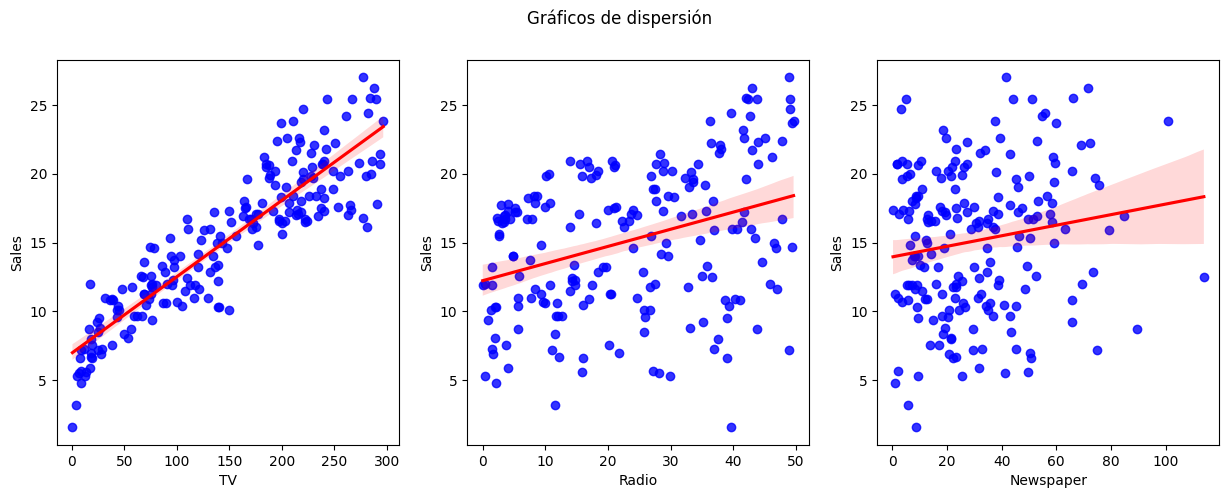

In [85]:
# Gráficos de dispersión
vars = ['TV', 'Radio', 'Newspaper']
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
for i, var in enumerate(vars):
    sns.regplot(x=var, y='Sales', data=df, ax=axs[i], scatter_kws={'color': 'blue'}, line_kws={'color': 'red'})
    axs[i].set_xlabel(var)
    axs[i].set_ylabel('Sales')
fig.suptitle('Gráficos de dispersión')
plt.show()

Pot lo visto, la unica variable que pareciera directamente proporcional es la publicidad en TV, ya que es la unica que conforme sube la inversion, suben las ventas

### 2.2: Correlación entre variables
1. Calcula la matriz de correlación.
2. Visualízala con un heatmap.
3. Responde: ¿Qué variables están más correlacionadas con `Sales`? ¿Hay correlación alta entre predictores?

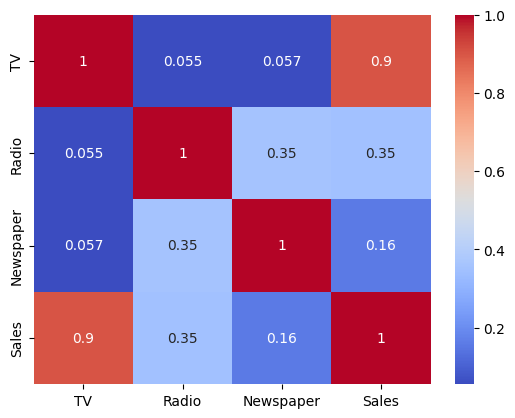

In [86]:
# Correlación y heatmap
matriz = df.corr()
sns.heatmap(matriz, annot=True, cmap='coolwarm')
plt.show()

Como lo mencione en el punto anterior, la publicdad de TV esta altamente relacionada con con sales, a diferencia de las demas, considerando que la publicidad en periodico no tiene ni un 20% de relacion

## Parte 3. Multicolinealidad
1. Calcula el VIF (Variance Inflation Factor) para cada predictor.
2. Crea un diagrama de barras  para mostrar el  VIF
3. Interpreta si hay multicolinealidad:
- ¿Alguna variable tiene un VIF mayor a 5 o mayor a 10?
- ¿Qué implicaciones tiene esto para el modelo?

Text(0, 0.5, 'VIF')

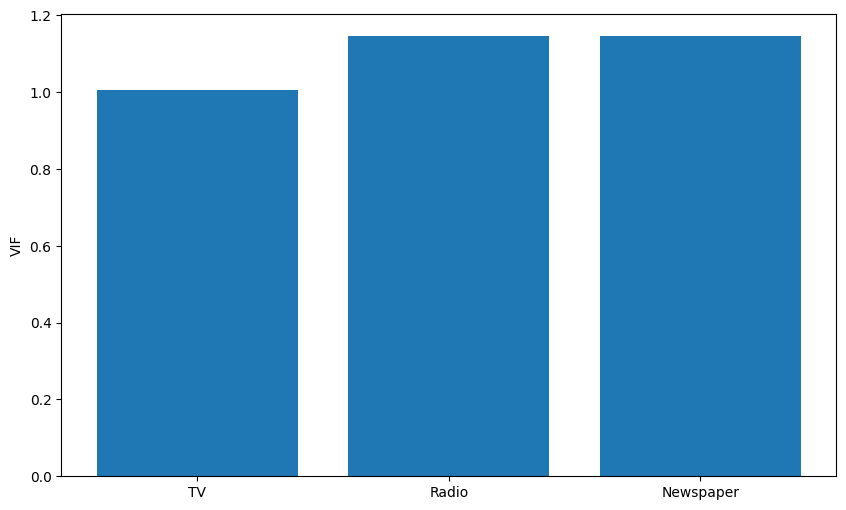

In [87]:
#Multicolinealidad
x = df[vars]
vif  = pd.DataFrame()
vif['VIF'] = [variance_inflation_factor(x.values, i) for i in range(x.shape[1])]
vif['variable'] = x.columns

plt.figure(figsize=(10, 6))
plt.bar(vif['variable'], vif['VIF'])
plt.ylabel('VIF')


Dado que el vif entre las mismas no supera el 1.2 para ninguna, podemos decir que no hay multicolinealidad entre las mismas, y estas parecieran ser independientes entre ellos

## Parte 4: Construcción del Modelo (Todas las variables Independientes), Evaluación

### 4.1 Entrenamiento del Modelo (Todas las Variables Independientes)

1. Entrena un modelo de regresión lineal múltiple usando TV, Radio y Newspaper como variables independientes.
2. Imprime el intercepto y los coeficientes del modelo.
3. Interpreta cada uno:
¿Qué significa cada uno de los coeficientes  en términos de ventas?

In [88]:
#ntrenamiento del Modelo (Todas las Variables Independientes)
x = df[vars]
y = df['Sales']
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
model = LinearRegression()
model.fit(x_train, y_train)
print("Intercepto:", model.intercept_)
# print("Coeficientes:", model.coef_)
for i, var in enumerate(vars):
    print("Columna:", var, " Coeficiente:",round(model.coef_[i],3))

Intercepto: 4.714126402214127
Columna: TV  Coeficiente: 0.055
Columna: Radio  Coeficiente: 0.101
Columna: Newspaper  Coeficiente: 0.004


Podemos ver aqui el que pareciera tener mejor renidmiento es el radio ya que es el que mejor relacion tiene a lo invertido, ya que es casi el doble, si lo comparamos con con el de la TV
Y podemos ver como el del periodico es el peor, siendo minimo.

### 4.2 Normalidad de los residuos

1. Calcula los residuos: residuos = y - y_pred.

2. Grafica un histograma con KDE de los residuos.

3. ¿Los residuos parecen distribuirse normalmente?

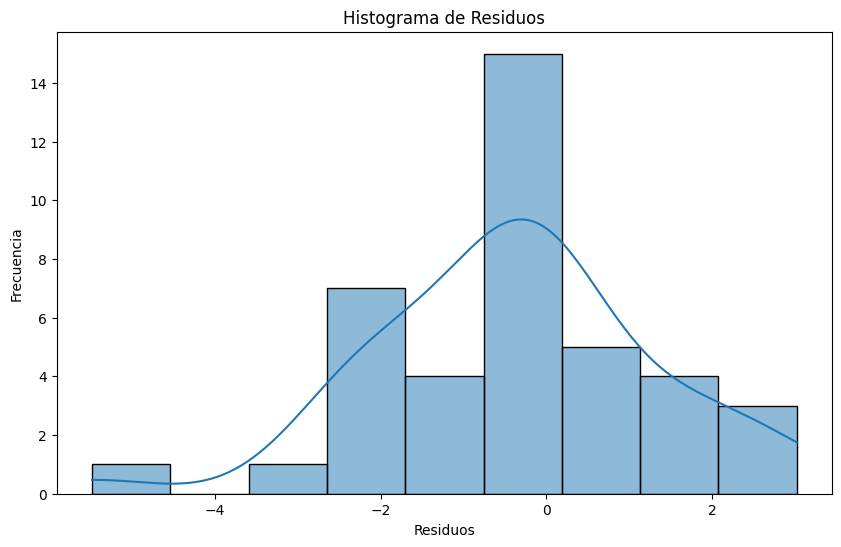

In [89]:
#Normalidad de los residuos
y_pred = model.predict(x_test)
residuos = y_test - y_pred
plt.figure(figsize=(10, 6))
sns.histplot(residuos, kde=True)
plt.xlabel('Residuos')
plt.ylabel('Frecuencia')
plt.title('Histograma de Residuos')
plt.show()

Aunque el punto mas alto si este en cero, se una posible cola mas larga de lado izquierdo, lo cual nos pudiera indicar que posiblemente haya outliers en ese rango y con la grafica podemos ver que la mayoria de errores se concentran en un rango de -4 a 2

### 4.3. Homocedasticidad

1. Grafica los residuos contra los valores predichos.
2. ¿Observas patrones? ¿Los residuos se dispersan aleatoriamente?

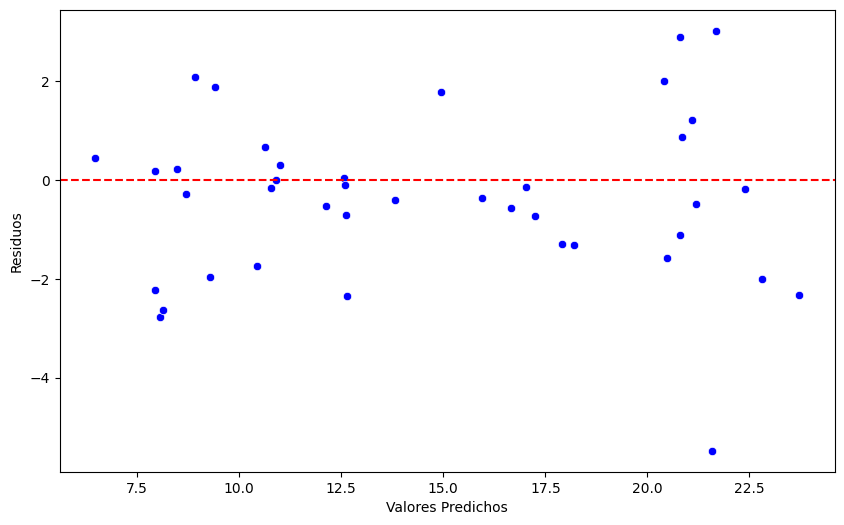

In [90]:
# Homocedasticidad

plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_pred, y=residuos, color="blue")
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel('Valores Predichos')
plt.ylabel('Residuos')
plt.show()

Los valores se distribuyen aleatoreamente al rededor de cero, y visualmente no se distingue ningun patron

### 4.4 Q-Q Plot

1. Graficar el Q-Q Plot
2. Interpreta el gráfico: a) Si los puntos se alinean aproximadamente sobre la línea diagonal, los residuos siguen una distribución normal, b) Desviaciones sistemáticas indican asimetría o colas pesadas.

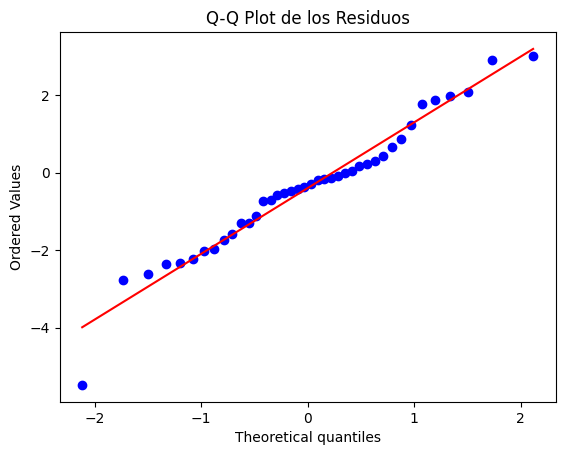

In [91]:
#Q-Q Plot
import scipy.stats as stats
stats.probplot(residuos, dist="norm", plot=plt)
plt.title("Q-Q Plot de los Residuos")
plt.show()

Por lo visto los puntos azules giran alrededor de la linea recta diagonal, lo que nos hace pensar que que los residuos se distribuyen normalmente, y pudieramos decir que el modelo es confiable

### 4.5. Evaluación del Modelo

1. Calcula las métricas: a) MSE (error cuadrático medio), b) RMSE (raíz del error cuadrático medio), c) R² (coeficiente de determinación)

2. ¿Qué nos dicen estas métricas sobre el ajuste del modelo?


In [92]:
#Evaluación del Modelo

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print("Error Cuadrático Medio (MSE):", round(mse,2))
print("Raíz del Error Cuadrático Medio (RMSE):", round(rmse,2))
print("Coeficiente de Determinación (R²):", round(r2,2))

Error Cuadrático Medio (MSE): 2.91
Raíz del Error Cuadrático Medio (RMSE): 1.71
Coeficiente de Determinación (R²): 0.91


Con el error cuadratico medio podemos ver que como se acerca a cero, los errores pudieran ser minimos. Y con el coeficiente de determinacion podemos saber, que tan determinante son las otras columnas de lo que queremos medir, que en este caso tiene un 91% de determinacion, asi que podemos decir que si son determinantes

### 4.6. Visualización de Predicciones

1. Crea un gráfico comparando Sales reales vs Sales predichas.

2. Puedes usar plt.scatter(y_true, y_pred) para evaluar visualmente el ajuste.
3.¿Qué observas?¿Qué observas? ¿Qué información puedes obtener de esta gráfica?

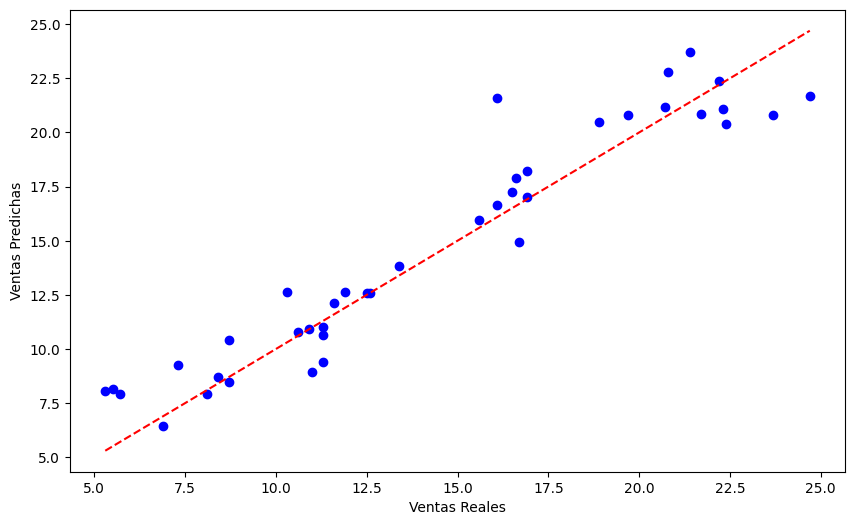

In [93]:
#Visualización de las Predicciones
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, color='blue')
min_val = min(min(y_test), min(y_pred))
max_val = max(max(y_test), max(y_pred))
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--')
plt.xlabel('Ventas Reales')
plt.ylabel('Ventas Predichas')
plt.show()


Con la grafica podemos ver como las ventas pre dichas no se alejan de las ventas reales, lo cual nos da a entender que el sistema tiene cierto grado de confiabilidad

### 4.7 Verificar el impacto de los atributos en el modelo

1. Ajusta el modelo usando statsmodels en lugar de scikit-learn para obtener los valores p.
2. Interpreta los resultados:

 - Observa los valores P>|t| en la tabla de salida.

 - ¿Qué variables tienen p-value menores a 0.05?

 - ¿Cuál es la conclusión sobre esas variables?


In [94]:
#P-values
x = sm.add_constant(x)
model = sm.OLS(y, x).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.903
Model:                            OLS   Adj. R-squared:                  0.901
Method:                 Least Squares   F-statistic:                     605.4
Date:                Fri, 30 Oct 2026   Prob (F-statistic):           8.13e-99
Time:                        03:37:25   Log-Likelihood:                -383.34
No. Observations:                 200   AIC:                             774.7
Df Residuals:                     196   BIC:                             787.9
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.6251      0.308     15.041      0.0

Viendo que el valor de P tanto de TV como de Radio son menores a 0.05 eso confirma que la inversion en TV y en Radio tienen un efecto lineal y significativo en ventas. Tambien podemos ver que newspaper tiene un valor arriba de 0.05 lo cual nos dice que ese no aporta un efecto siginificativo en las ventas

##Parte 5:  Construcción del Modelo (sin Multicolinealidad), Evaluación

En el caso de que hayas detectado variables con multicolinealidad. Elimina aquellas que presenten esta característica y realiza los mismos pasos** que la parte 4.**
Escribe cada una de las subsecciones similares a las existentes en la Parte 4.

5.1 Entrenamiento del Modelo

In [95]:
## Realmente ninguna de las columnas representba multicolinealidad,
## pero ya que newspaper fue el que dio el resultado mas alto en
## la actividad pasada, vamos a eliminar ese

x2 = df.drop('Newspaper', axis=1)
y2 = df['Sales']
x2_train, x2_test, y2_train, y2_test = train_test_split(x2, y2, test_size=0.2, random_state=42)
model2 = LinearRegression()
model2.fit(x2_train, y2_train)
print("Intercepto:", model2.intercept_)
for i, var in enumerate(x2.columns):
    print("Columna:", var, " Coeficiente:",round(model2.coef_[i],3))


Intercepto: 3.552713678800501e-15
Columna: TV  Coeficiente: -0.0
Columna: Radio  Coeficiente: -0.0
Columna: Sales  Coeficiente: 1.0


5.2 Normalidad de los residuos

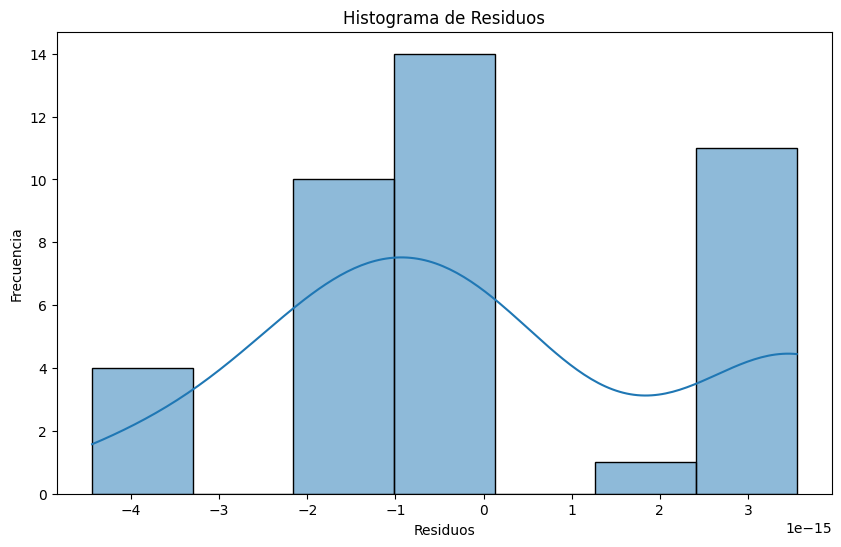

In [96]:
y2_pred = model2.predict(x2_test)
residuos2 = y2_test - y2_pred
plt.figure(figsize=(10, 6))
sns.histplot(residuos2, kde=True)
plt.xlabel('Residuos')
plt.ylabel('Frecuencia')
plt.title('Histograma de Residuos')
plt.show()

5.3. Homocedasticidad

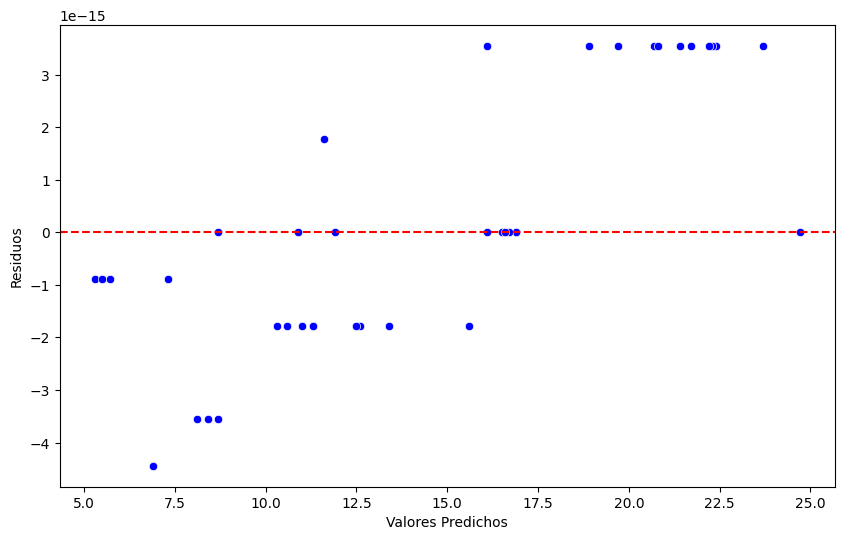

In [97]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x=y2_pred, y=residuos2, color="blue")
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel('Valores Predichos')
plt.ylabel('Residuos')
plt.show()


5.4 Q-Q Plot

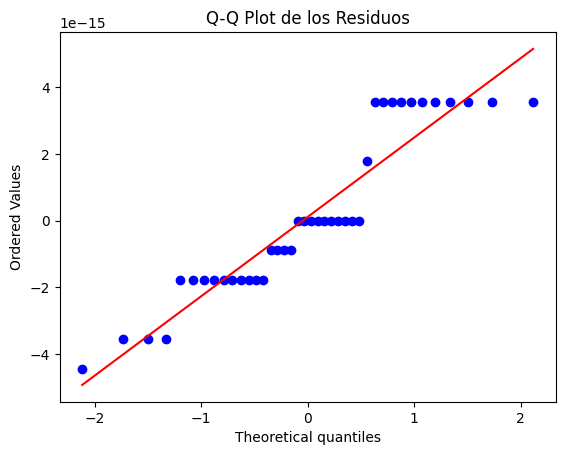

In [98]:
stats.probplot(residuos2, dist="norm", plot=plt)
plt.title("Q-Q Plot de los Residuos")
plt.show()

5.5. Evaluación del Modelo

In [99]:
mse2 = mean_squared_error(y2_test, y2_pred)
rmse2 = np.sqrt(mse)
r3 = r2_score(y2_test, y2_pred)
print("Error Cuadrático Medio (MSE):", round(mse2,2))
print("Raíz del Error Cuadrático Medio (RMSE):", round(rmse2,2))
print("Coeficiente de Determinación (R²):", round(r3,2))

Error Cuadrático Medio (MSE): 0.0
Raíz del Error Cuadrático Medio (RMSE): 1.71
Coeficiente de Determinación (R²): 1.0


5.6. Visualización de Predicciones

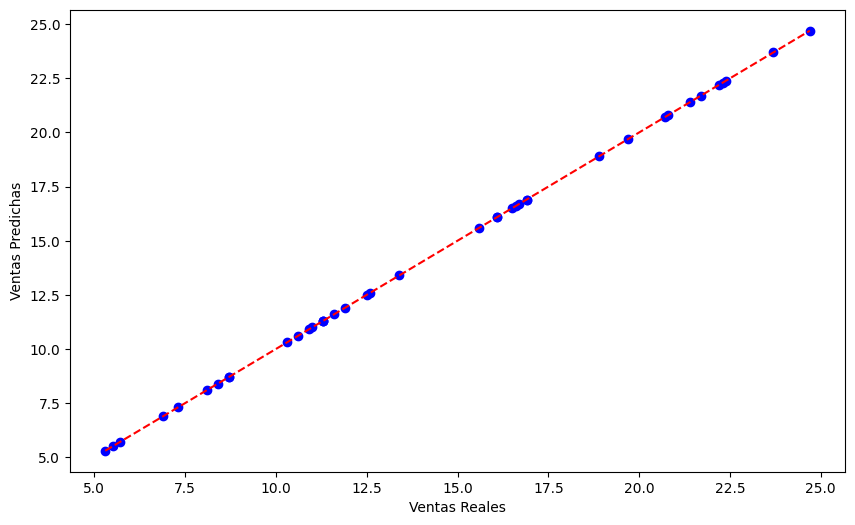

In [100]:
plt.figure(figsize=(10, 6))
plt.scatter(y2_test, y2_pred, color='blue')
min_val = min(min(y2_test), min(y2_pred))
max_val = max(max(y2_test), max(y2_pred))
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--')
plt.xlabel('Ventas Reales')
plt.ylabel('Ventas Predichas')
plt.show()

5.7 Verificar el impacto de los atributos en el modelo

In [101]:
x2 = sm.add_constant(x2)
model2 = sm.OLS(y2, x2).fit()
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                  1.000
Method:                 Least Squares   F-statistic:                 9.785e+30
Date:                Fri, 30 Oct 2026   Prob (F-statistic):               0.00
Time:                        03:37:28   Log-Likelihood:                 6101.7
No. Observations:                 200   AIC:                        -1.220e+04
Df Residuals:                     196   BIC:                        -1.218e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -6.661e-15   3.65e-15     -1.826      0.0

## Parte 6: Construcción del Modelo (sin variables que no muestran una relación lineal), Evaluación

En el caso de que hayas detectado variables sin una relación lineal con la variable dependiente. Elimina aquellas que presenten esta característica y realiza lo siguiente.

En el caso de que hayas detectado variables sin una relación lineal. Elimina aquellas que presenten esta característica y realiza los mismos pasos** que la parte 4.**
Escribe cada una de las subsecciones similares a las existentes en la Parte 4.

6.1 Entrenamiento del Modelo

In [102]:
## Ahora quitamos la que mas relacion tenia que era la del radio, para ver como se comporta las predicciones del dataset
df_3 = df.drop('Radio', axis=1)
x3 = df_3.drop('Sales', axis=1)
y3 = df_3['Sales']
x3_train, x3_test, y3_train, y3_test = train_test_split(x3, y3, test_size=0.2, random_state=42)
model3 = LinearRegression()
model3.fit(x3_train, y3_train)
print("Intercepto:", model3.intercept_)
for i, var in enumerate(x3.columns):
    print("Columna:", var, " Coeficiente:",round(model3.coef_[i],3))

Intercepto: 6.047780669094935
Columna: TV  Coeficiente: 0.055
Columna: Newspaper  Coeficiente: 0.033


6.2 Normalidad de los residuos


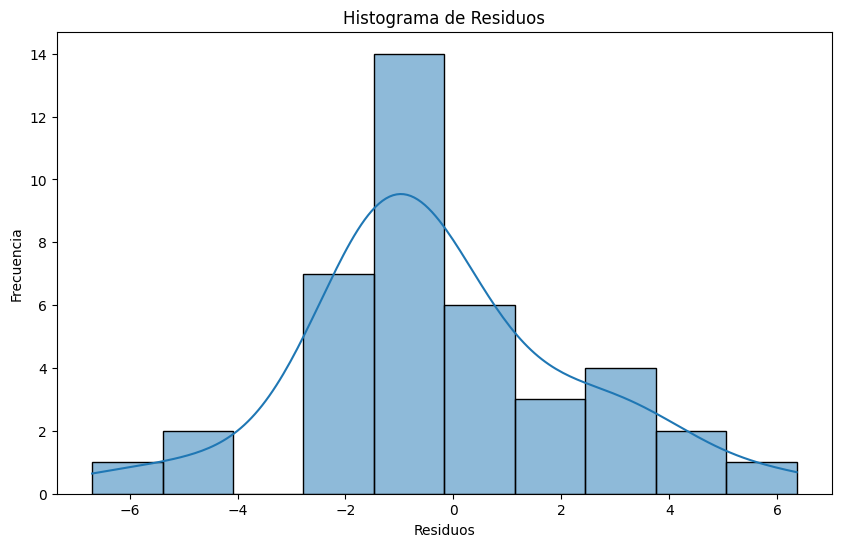

In [103]:
y3_pred = model3.predict(x3_test)
residuos3 = y3_test - y3_pred
plt.figure(figsize=(10, 6))
sns.histplot(residuos3, kde=True)
plt.xlabel('Residuos')
plt.ylabel('Frecuencia')
plt.title('Histograma de Residuos')
plt.show()

6.3. Homocedasticidad

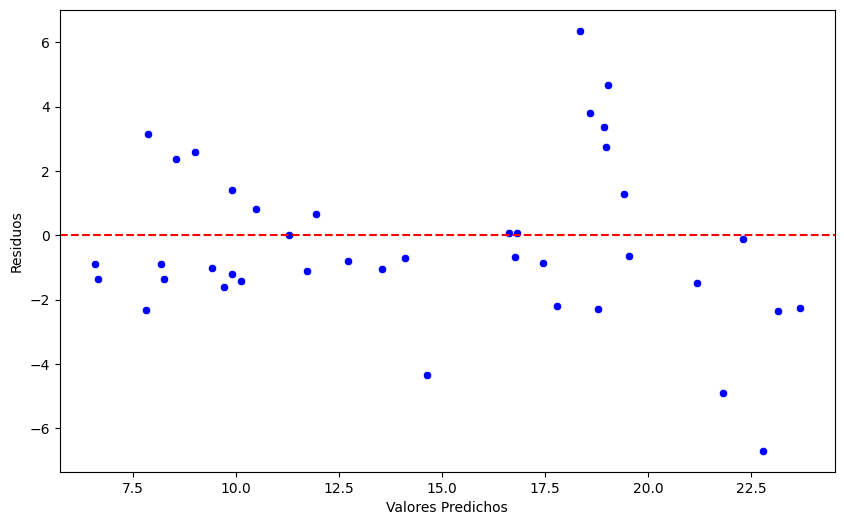

In [104]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x=y3_pred, y=residuos3, color="blue")
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel('Valores Predichos')
plt.ylabel('Residuos')
plt.show()

6.4 Q-Q Plot

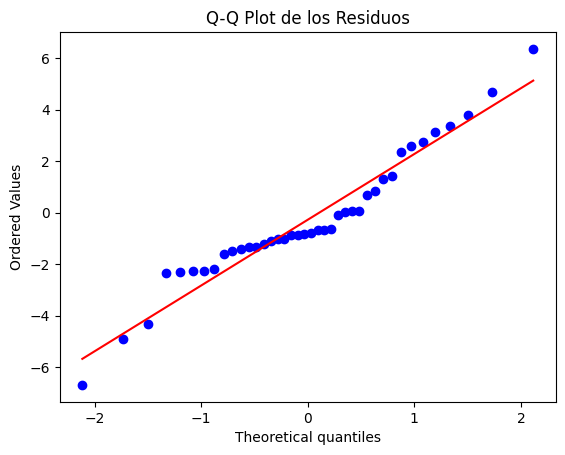

In [105]:
stats.probplot(residuos3, dist="norm", plot=plt)
plt.title("Q-Q Plot de los Residuos")
plt.show()

6.5. Evaluación del Modelo

In [106]:
mse3 = mean_squared_error(y3_test, y3_pred)
rmse3 = np.sqrt(mse)
r4 = r2_score(y3_test, y3_pred)
print("Error Cuadrático Medio (MSE):", round(mse3,2))
print("Raíz del Error Cuadrático Medio (RMSE):", round(rmse3,2))
print("Coeficiente de Determinación (R²):", round(r4,2))

Error Cuadrático Medio (MSE): 6.4
Raíz del Error Cuadrático Medio (RMSE): 1.71
Coeficiente de Determinación (R²): 0.79


6.6. Visualización de Predicciones

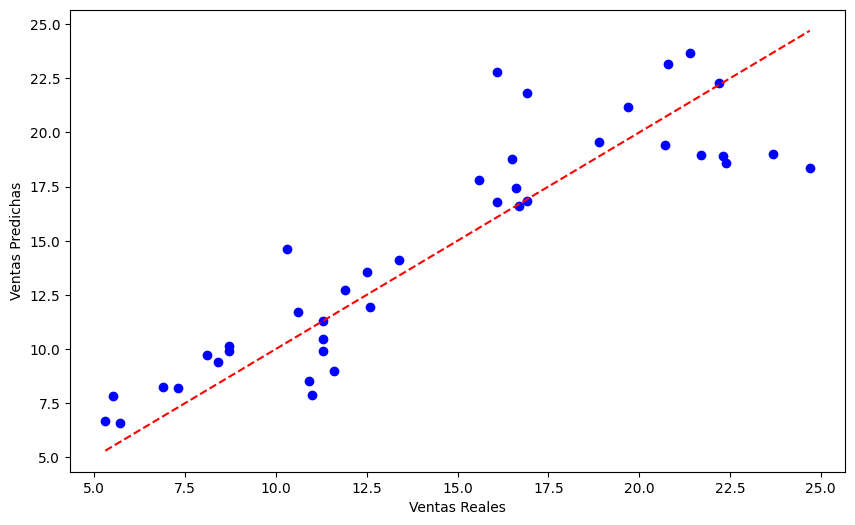

In [107]:
plt.figure(figsize=(10, 6))
plt.scatter(y3_test, y3_pred, color='blue')
min_val = min(min(y3_test), min(y3_pred))
max_val = max(max(y3_test), max(y3_pred))
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--')
plt.xlabel('Ventas Reales')
plt.ylabel('Ventas Predichas')
plt.show()

6.7 Verificar el impacto de los atributos en el modelo

In [108]:
x3 = sm.add_constant(x3)
model3 = sm.OLS(y3, x3).fit()
print(model3.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.824
Model:                            OLS   Adj. R-squared:                  0.822
Method:                 Least Squares   F-statistic:                     460.0
Date:                Fri, 30 Oct 2026   Prob (F-statistic):           5.89e-75
Time:                        03:37:31   Log-Likelihood:                -442.70
No. Observations:                 200   AIC:                             891.4
Df Residuals:                     197   BIC:                             901.3
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          6.2347      0.375     16.607      0.0

##7. Conclusiones.

¿Cuál de los tres modelos construidos fue el mejor?
¿Cuál fue el atributo que mas influencia tiene en las ventas?



Por lo visto el modelo que mejor se comporto fue donde eliminamos el newspaper y dejamos solo TV y radio, ya que son las que mas relacion lineal tenian con las ventas, y se puede ver en los graficos donde se ajustan mejor por ejemplo en el qplot, los residuos se distribuyen de forma equitativa sobre la linea, lo cual nos dice que se distribuyen normalmente, y esto genera confianza en el modelo, aunque el histograma no pareciera tener una distribucion normal. El coeficiente de determinacion es practicamente del 100%, lo cual nos dice que sales es totalmente dependiente de las dos variables que estamos dejando para el modelo.
Podemos decir que el atributo que mas influye en el modelo, es el radio.